<a href="https://colab.research.google.com/github/KadeejaHibaPT/AML_lab/blob/main/AML%20exp%20_5%2C6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


ONE-CLASS SVM: NOVELTY DETECTION
---------------------------------------------
Training samples: 41
Testing samples: 137
Number of features: 13

Confusion Matrix
Rows = Actual [Normal, Novel]
Columns = Predicted [Normal, Novel]
[[  9   9]
 [  0 119]]

Evaluation Metrics
Accuracy  : 0.9343
Precision : 0.9297
Recall    : 1.0000
F1-score  : 0.9636

Classification Report
              precision    recall  f1-score   support

      Normal       1.00      0.50      0.67        18
       Novel       0.93      1.00      0.96       119

    accuracy                           0.93       137
   macro avg       0.96      0.75      0.82       137
weighted avg       0.94      0.93      0.92       137


Total variance retained by PCA: 0.4639


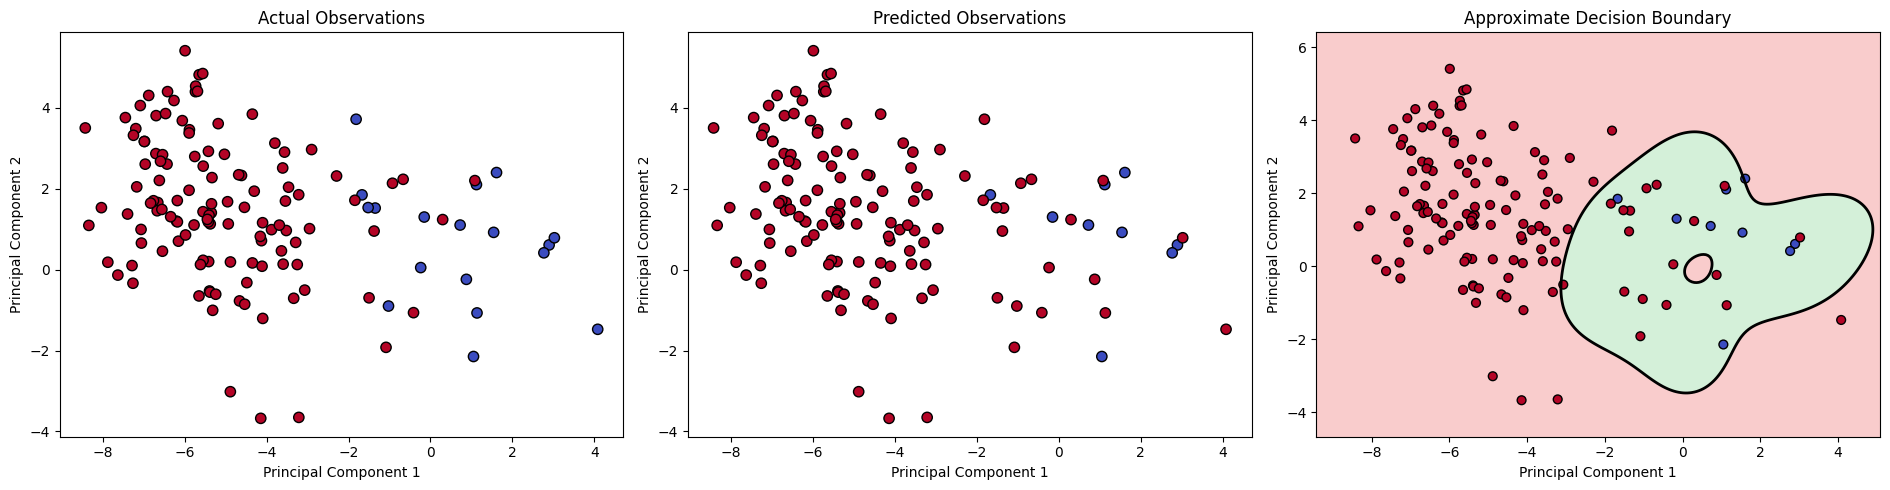

In [1]:


# EXPERIMENT 5: ONE-CLASS SVM FOR NOVELTY DETECTION

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM
from sklearn.decomposition import PCA
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, classification_report
)

# --------------------------------------------------
# 1. Load dataset
# --------------------------------------------------
wine = load_wine()
X = wine.data
y = wine.target

# Normal = class 0; Novel = classes 1 and 2
X_normal = X[y == 0]
X_novel = X[y != 0]

# --------------------------------------------------
# 2. Split normal and novel observations
# --------------------------------------------------
X_train, X_normal_test = train_test_split(
    X_normal, test_size=0.30, random_state=42
)

# Keep some novel observations for testing only
X_novel_test = X_novel

X_test = np.vstack((X_normal_test, X_novel_test))

# Actual labels: 1 = normal, -1 = novel
y_test = np.concatenate((
    np.ones(len(X_normal_test), dtype=int),
    -np.ones(len(X_novel_test), dtype=int)
))

# --------------------------------------------------
# 3. Feature standardization
# --------------------------------------------------
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# --------------------------------------------------
# 4. Train One-Class SVM using RBF kernel
# --------------------------------------------------
model = OneClassSVM(
    kernel='rbf',
    gamma='scale',
    nu=0.10
)

model.fit(X_train_scaled)

# --------------------------------------------------
# 5. Predict normal and novel observations
# --------------------------------------------------
y_pred = model.predict(X_test_scaled)

# Convert labels into anomaly-detection labels:
# 0 = normal, 1 = novel
y_true_binary = (y_test == -1).astype(int)
y_pred_binary = (y_pred == -1).astype(int)

# --------------------------------------------------
# 6. Evaluation
# --------------------------------------------------
cm = confusion_matrix(
    y_true_binary, y_pred_binary, labels=[0, 1]
)

print("\nONE-CLASS SVM: NOVELTY DETECTION")
print("-" * 45)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Number of features:", X.shape[1])

print("\nConfusion Matrix")
print("Rows = Actual [Normal, Novel]")
print("Columns = Predicted [Normal, Novel]")
print(cm)

print("\nEvaluation Metrics")
print(f"Accuracy  : {accuracy_score(y_true_binary, y_pred_binary):.4f}")
print(f"Precision : {precision_score(y_true_binary, y_pred_binary, zero_division=0):.4f}")
print(f"Recall    : {recall_score(y_true_binary, y_pred_binary, zero_division=0):.4f}")
print(f"F1-score  : {f1_score(y_true_binary, y_pred_binary, zero_division=0):.4f}")

print("\nClassification Report")
print(classification_report(
    y_true_binary, y_pred_binary,
    labels=[0, 1],
    target_names=["Normal", "Novel"],
    zero_division=0
))

# --------------------------------------------------
# 7. PCA: reduce 13 features to 2 dimensions
# --------------------------------------------------
pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("\nTotal variance retained by PCA:",
      f"{pca.explained_variance_ratio_.sum():.4f}")

# --------------------------------------------------
# 8. Approximate decision boundary in PCA space
# --------------------------------------------------
# This is a separate 2D model used only for visualization.
model_2d = OneClassSVM(
    kernel='rbf',
    gamma='scale',
    nu=0.10
)
model_2d.fit(X_train_pca)

x_min = X_test_pca[:, 0].min() - 1
x_max = X_test_pca[:, 0].max() + 1
y_min = X_test_pca[:, 1].min() - 1
y_max = X_test_pca[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)

grid = np.c_[xx.ravel(), yy.ravel()]
Z = model_2d.decision_function(grid).reshape(xx.shape)

# --------------------------------------------------
# 9. Visualization
# --------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# Actual observations
axes[0].scatter(
    X_test_pca[:, 0], X_test_pca[:, 1],
    c=y_true_binary, cmap='coolwarm',
    edgecolors='black', s=55
)
axes[0].set_title("Actual Observations")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")

# Predicted observations
axes[1].scatter(
    X_test_pca[:, 0], X_test_pca[:, 1],
    c=y_pred_binary, cmap='coolwarm',
    edgecolors='black', s=55
)
axes[1].set_title("Predicted Observations")
axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")

# Approximate decision boundary
axes[2].contourf(
    xx, yy, Z, levels=[Z.min(), 0, Z.max()],
    colors=['#f5aaaa', '#b8e6c1'], alpha=0.6
)
axes[2].contour(
    xx, yy, Z, levels=[0], colors='black', linewidths=2
)
axes[2].scatter(
    X_test_pca[:, 0], X_test_pca[:, 1],
    c=y_pred_binary, cmap='coolwarm',
    edgecolors='black', s=40
)
axes[2].set_title("Approximate Decision Boundary")
axes[2].set_xlabel("Principal Component 1")
axes[2].set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()





Iris dataset loaded successfully!
Total samples: 150
Total features: 4
Target classes: ['setosa' 'versicolor' 'virginica']

Decision Tree using Gini Impurity
Training Accuracy: 1.0

Random Forest
Number of Trees: 100
Training Accuracy: 1.0

Gradient Boosting
Number of Trees: 100
Learning Rate: 0.1
Training Accuracy: 1.0

5-Fold Cross-Validation Results:
            Model  Fold 1  Fold 2  Fold 3  Fold 4  Fold 5  Mean Accuracy  Standard Deviation
    Decision Tree  1.0000  0.9667  0.9333  0.9667     0.9         0.9533              0.0340
    Random Forest  0.9667  0.9667  0.9333  0.9667     0.9         0.9467              0.0267
Gradient Boosting  1.0000  0.9667  0.9333  0.9667     0.9         0.9533              0.0340


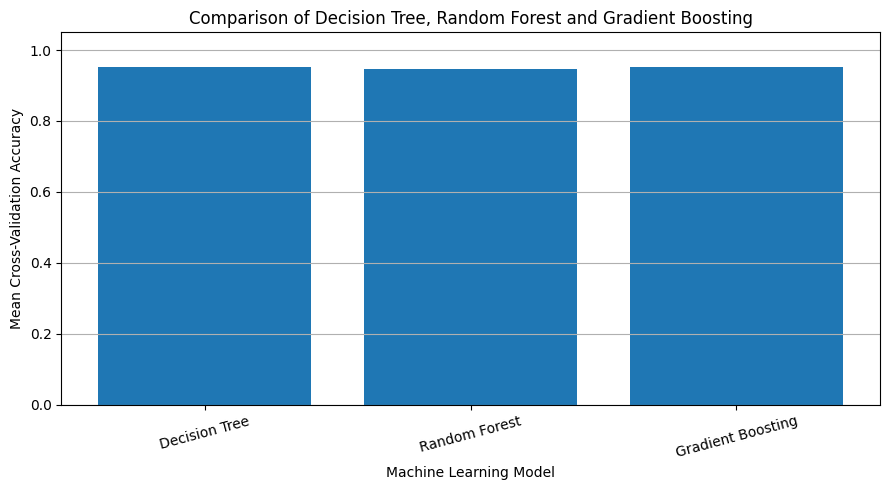


Conclusion:
Gradient Boosting performs better based on mean cross-validation accuracy.

Decision Tree, Random Forest and Gradient Boosting
were evaluated using 5-fold cross-validation.
Mean accuracy and standard deviation were compared.


In [2]:


# Experiment 6: Random Forest and Gradient Boosting
# Aim: Implement Random Forest and Gradient Boosting and compare performance
# Dataset: Iris dataset (sklearn.datasets.load_iris)

# Step 1: Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score

# Step 2: Load the dataset
iris = load_iris()
X = iris.data
y = iris.target

print("Iris dataset loaded successfully!")
print("Total samples:", len(X))
print("Total features:", X.shape[1])
print("Target classes:", iris.target_names)

# Step 3: Implement Decision Tree using Gini impurity
dt_model = DecisionTreeClassifier(
    criterion='gini',
    random_state=42
)

dt_model.fit(X, y)

y_pred_dt = dt_model.predict(X)

accuracy_dt = accuracy_score(y, y_pred_dt)

print("\nDecision Tree using Gini Impurity")
print("Training Accuracy:", round(accuracy_dt, 4))

# Step 4: Implement Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    criterion='gini',
    max_features='sqrt',
    bootstrap=True,
    random_state=42
)

rf_model.fit(X, y)

y_pred_rf = rf_model.predict(X)

accuracy_rf = accuracy_score(y, y_pred_rf)

print("\nRandom Forest")
print("Number of Trees:", rf_model.n_estimators)
print("Training Accuracy:", round(accuracy_rf, 4))

# Step 5: Implement Gradient Boosting
gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb_model.fit(X, y)

y_pred_gb = gb_model.predict(X)

accuracy_gb = accuracy_score(y, y_pred_gb)

print("\nGradient Boosting")
print("Number of Trees:", gb_model.n_estimators)
print("Learning Rate:", gb_model.learning_rate)
print("Training Accuracy:", round(accuracy_gb, 4))

# Step 6: Perform 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    'Decision Tree': DecisionTreeClassifier(
        criterion='gini',
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        criterion='gini',
        max_features='sqrt',
        bootstrap=True,
        random_state=42
    ),

    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X,
        y,
        cv=cv,
        scoring='accuracy'
    )

    results.append({
        'Model': name,
        'Fold 1': round(scores[0], 4),
        'Fold 2': round(scores[1], 4),
        'Fold 3': round(scores[2], 4),
        'Fold 4': round(scores[3], 4),
        'Fold 5': round(scores[4], 4),
        'Mean Accuracy': round(scores.mean(), 4),
        'Standard Deviation': round(scores.std(), 4)
    })

# Step 7: Display the comparison table
results_df = pd.DataFrame(results)

print("\n5-Fold Cross-Validation Results:")
print(results_df.to_string(index=False))

# Step 8: Visualize model performance
plt.figure(figsize=(9, 5))

plt.bar(
    results_df['Model'],
    results_df['Mean Accuracy']
)

plt.xlabel('Machine Learning Model')
plt.ylabel('Mean Cross-Validation Accuracy')
plt.title('Comparison of Decision Tree, Random Forest and Gradient Boosting')
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

# Step 9: Display the better-performing ensemble model
rf_mean = results_df.loc[
    results_df['Model'] == 'Random Forest',
    'Mean Accuracy'
].iloc[0]

gb_mean = results_df.loc[
    results_df['Model'] == 'Gradient Boosting',
    'Mean Accuracy'
].iloc[0]

print("\nConclusion:")

if rf_mean > gb_mean:
    print("Random Forest performs better based on mean cross-validation accuracy.")
elif gb_mean > rf_mean:
    print("Gradient Boosting performs better based on mean cross-validation accuracy.")
else:
    print("Both models have equal mean cross-validation accuracy.")

print("\nDecision Tree, Random Forest and Gradient Boosting")
print("were evaluated using 5-fold cross-validation.")
print("Mean accuracy and standard deviation were compared.")